## Chapter 1: Data Collection

Before we can fit a surrogate model or run Bayesian Optimization, we need data.
This chapter collects that data in three simple steps:
1. Sample 128 random-but-well-spread recipes (Sobol sampling)
2. Test all of them on all 3 scales (micro, bench, pilot)
3. Pick 12 interesting recipes and repeat them 5x to measure noise

In [3]:
import numpy as np
import pandas as pd
import time, sys
from scipy.stats import qmc
sys.path.insert(0, ".")
from basic_client import BioreactorClient, USER, PASSWORD

# The 5 parameters we can control, and their min/max allowed values
param_names = ["T", "pH", "F1", "F2", "F3"]
lower_bounds = [20.0, 3.0, 0.0, 0.0, 0.0]
upper_bounds = [60.0, 9.5, 2.0, 2.0, 2.0]

scales = ["micro", "bench", "pilot"]

n_recipes = 128   # how many different recipes to try
n_repeats = 5     # how many times to repeat each chosen recipe

### Step 1: Generate 128 recipes with Sobol sampling

A Sobol sequence is just a smart way of picking "random" points that
spread out evenly across the space, instead of clumping together like
normal random numbers would. This gives us good coverage of all 5 parameters.

In [4]:
# Sobol sampler needs n_recipes to be a power of 2 (128 = 2^7)
sampler = qmc.Sobol(d=len(param_names), scramble=True)
unit_samples = sampler.random_base2(m=7)  # 2^7 = 128 points, values between 0 and 1

# Stretch the 0-1 values out to our real parameter ranges
scaled_samples = qmc.scale(unit_samples, lower_bounds, upper_bounds)

recipes = pd.DataFrame(scaled_samples, columns=param_names)
recipes.head()

,T,pH,F1,F2,F3
0,58.300487,4.249245,0.123925,0.964358,0.436022
1,31.358835,6.960814,1.821471,1.782133,1.945919
2,21.618574,6.156873,0.915924,0.226471,1.473379
3,48.743925,8.448742,1.154474,1.027892,0.892937
4,40.416985,4.818437,1.616103,1.393200,0.561090


### Step 2: Connect to the simulator

In [6]:
client = BioreactorClient()
client.login(USER, PASSWORD)
print("Logged in successfully.")

Logged in successfully.


### Step 3: Run all 128 recipes on all 3 scales

This is our "exploration" data — a broad first look at how yield behaves
across the whole parameter space, at every scale.

In [7]:
exploration_results = []

for recipe_id in range(n_recipes):
    recipe = recipes.loc[recipe_id]
    
    for scale in scales:
        result = client.run(
            scale=scale,
            T=recipe["T"], pH=recipe["pH"],
            F1=recipe["F1"], F2=recipe["F2"], F3=recipe["F3"]
        )
        
        exploration_results.append({
            "recipe_id": recipe_id,
            "scale": scale,
            "T": recipe["T"], "pH": recipe["pH"],
            "F1": recipe["F1"], "F2": recipe["F2"], "F3": recipe["F3"],
            "yield": result["Y"],
            "cost": result["cost_eur"]
        })
        
        time.sleep(0.1)  # be nice to the server

    if recipe_id % 20 == 0:
        print(f"Done with recipe {recipe_id}/{n_recipes}")

df_exploration = pd.DataFrame(exploration_results)
print(f"Collected {len(df_exploration)} data points.")

Done with recipe 0/128
  [rate-limited, sleeping 1.0s]
  [rate-limited, sleeping 2.5s]
  [rate-limited, sleeping 6.2s]
  [rate-limited, sleeping 15.6s]
  [rate-limited, sleeping 39.1s]
  [rate-limited, sleeping 1.0s]
  [rate-limited, sleeping 2.5s]
  [rate-limited, sleeping 6.2s]
  [rate-limited, sleeping 15.6s]
  [rate-limited, sleeping 39.1s]
Done with recipe 20/128
  [rate-limited, sleeping 1.0s]
  [rate-limited, sleeping 2.5s]
  [rate-limited, sleeping 6.2s]
  [rate-limited, sleeping 15.6s]
  [rate-limited, sleeping 39.1s]
  [rate-limited, sleeping 1.0s]
  [rate-limited, sleeping 2.5s]
  [rate-limited, sleeping 6.2s]
  [rate-limited, sleeping 15.6s]
  [rate-limited, sleeping 39.1s]
Done with recipe 40/128
  [rate-limited, sleeping 1.0s]
  [rate-limited, sleeping 2.5s]
  [rate-limited, sleeping 6.2s]
  [rate-limited, sleeping 15.6s]
  [rate-limited, sleeping 39.1s]
  [rate-limited, sleeping 1.0s]
  [rate-limited, sleeping 2.5s]
  [rate-limited, sleeping 6.2s]
  [rate-limited, sleepi

### Step 4: Pick 12 recipes to repeat

We want a mix: some recipes that gave low yield, some medium, some high.
We use the pilot-scale results to sort recipes by yield, then take 4 from
each third of that list.

In [8]:
# Only look at pilot-scale results, sorted worst to best yield
pilot_results = df_exploration[df_exploration["scale"] == "pilot"]
pilot_results = pilot_results.sort_values("yield").reset_index(drop=True)

n = len(pilot_results)
low_group = pilot_results.iloc[0 : n//3]
mid_group = pilot_results.iloc[n//3 : 2*n//3]
high_group = pilot_results.iloc[2*n//3 : n]

# Take 4 random recipes from each group
chosen_low = low_group.sample(4, random_state=42)
chosen_mid = mid_group.sample(4, random_state=42)
chosen_high = high_group.sample(4, random_state=42)

chosen_recipe_ids = pd.concat([chosen_low, chosen_mid, chosen_high])["recipe_id"].values
print("Recipes we'll repeat:", chosen_recipe_ids)

Recipes we'll repeat: [ 26  32  84  92  43  55 100 109  22  49  60  41]


### Step 5: Repeat the 12 chosen recipes 5 times each

Running the same recipe multiple times tells us how noisy the simulator's
measurements are — same input, but the output will vary a bit each time.

In [9]:
repeat_results = []

for repeat_number in range(1, n_repeats + 1):
    for recipe_id in chosen_recipe_ids:
        recipe = recipes.loc[recipe_id]
        
        for scale in scales:
            result = client.run(
                scale=scale,
                T=recipe["T"], pH=recipe["pH"],
                F1=recipe["F1"], F2=recipe["F2"], F3=recipe["F3"]
            )
            
            repeat_results.append({
                "recipe_id": recipe_id,
                "scale": scale,
                "repeat": repeat_number,
                "T": recipe["T"], "pH": recipe["pH"],
                "F1": recipe["F1"], "F2": recipe["F2"], "F3": recipe["F3"],
                "yield": result["Y"],
                "cost": result["cost_eur"]
            })
            
            time.sleep(0.1)

    print(f"Finished repeat {repeat_number}/{n_repeats}")

df_repeats = pd.DataFrame(repeat_results)

  [rate-limited, sleeping 1.0s]
  [rate-limited, sleeping 2.5s]
  [rate-limited, sleeping 6.2s]
  [rate-limited, sleeping 15.6s]
  [rate-limited, sleeping 39.1s]
Finished repeat 1/5
  [rate-limited, sleeping 1.0s]
  [rate-limited, sleeping 2.5s]
  [rate-limited, sleeping 6.2s]
  [rate-limited, sleeping 15.6s]
  [rate-limited, sleeping 39.1s]
Finished repeat 2/5
  [rate-limited, sleeping 1.0s]
  [rate-limited, sleeping 2.5s]
  [rate-limited, sleeping 6.2s]
  [rate-limited, sleeping 15.6s]
  [rate-limited, sleeping 39.1s]
Finished repeat 3/5
  [rate-limited, sleeping 1.0s]
  [rate-limited, sleeping 2.5s]
  [rate-limited, sleeping 6.2s]
  [rate-limited, sleeping 15.6s]
  [rate-limited, sleeping 39.1s]
Finished repeat 4/5
  [rate-limited, sleeping 1.0s]
  [rate-limited, sleeping 2.5s]
  [rate-limited, sleeping 6.2s]
  [rate-limited, sleeping 15.6s]
  [rate-limited, sleeping 39.1s]
Finished repeat 5/5


### Step 6: Save everything

Combine the exploration data and the repeat data into one file, so we
don't have to re-run the simulator every time we reopen this notebook.

In [10]:
df_exploration["phase"] = "exploration"
df_repeats["phase"] = "repeat"

df_all = pd.concat([df_exploration, df_repeats], ignore_index=True)
df_all.to_csv("task1_2_data.csv", index=False)

print(f"Saved {len(df_all)} total rows to task1_2_data.csv")

Saved 564 total rows to task1_2_data.csv


## Chapter 2: Quantifying Noise and Bias Across Scales

Now that `task1_2_data.csv` exists, we compute the two numbers the report
actually needs:

- **Noise** — how much a *repeated* recipe wobbles at each scale (mean, std,
  and CV from the 5 repeats of the 12 chosen recipes).
- **Bias** — how much a scale's yield *systematically* differs from pilot for
  the *same* recipe, using all 128 exploration recipes (1 run each, but 128
  of them, so the systematic trend is easy to separate from noise).

Both numbers get reused later: noise (as variance) feeds `WhiteKernel`,
bias (intercept/slope) is what you'd use to align Micro/Bench predictions
onto the Pilot scale if you go with independent per-scale GPs.

In [13]:
# These imports are repeated here on purpose, so this chapter also runs
# standalone in a fresh kernel -- you only need task1_2_data.csv on disk,
# not a live re-run of Chapter 1's simulator calls.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("task1_2_data.csv")

scales = ["micro", "bench", "pilot"]

df_repeat = df[df["phase"] == "repeat"].copy()
df_explore = df[df["phase"] == "exploration"].copy()

chosen_recipe_ids = sorted(df_repeat["recipe_id"].unique())
n_recipes_explored = df_explore["recipe_id"].nunique()
n_repeats = df_repeat["repeat"].nunique()

print(f"Exploration rows: {len(df_explore)}  ({n_recipes_explored} recipes x {len(scales)} scales)")
print(f"Repeat rows:      {len(df_repeat)}  ({len(chosen_recipe_ids)} recipes x {n_repeats} repeats x {len(scales)} scales)")
df_repeat.head()

Exploration rows: 384  (128 recipes x 3 scales)
Repeat rows:      180  (12 recipes x 5 repeats x 3 scales)


,recipe_id,scale,T,pH,F1,F2,F3,yield,cost,phase,repeat
384,26,micro,27.848416,4.924700,1.240325,1.882159,0.318942,0.119624,10,repeat,1.0
385,26,bench,27.848416,4.924700,1.240325,1.882159,0.318942,3.117579,500,repeat,1.0
386,26,pilot,27.848416,4.924700,1.240325,1.882159,0.318942,1.231979,2000,repeat,1.0
387,32,micro,59.693520,6.137274,1.629949,1.840720,0.040585,0.129193,10,repeat,1.0
388,32,bench,59.693520,6.137274,1.629949,1.840720,0.040585,2.849614,500,repeat,1.0


### Step 1: Per-recipe noise (mean, std, CV) at each scale

For each of the 12 repeated recipes, at each scale, we compute the mean,
raw std, and CV (%) across the 5 repeats — the same table we built by hand
for recipe 26 last time, now for all 12 at once.

In [14]:
noise_stats = (
    df_repeat.groupby(["recipe_id", "scale"])["yield"]
    .agg(mean="mean", std="std", n="count")
    .reset_index()
)
noise_stats["cv_pct"] = 100 * noise_stats["std"] / noise_stats["mean"]

# Wide view: one row per recipe, columns grouped by scale -> easy to eyeball
noise_wide = noise_stats.pivot(index="recipe_id", columns="scale",
                                values=["mean", "std", "cv_pct"])
noise_wide = noise_wide.round(4)
noise_wide

mean                     std                  cv_pct           \
scale       bench   micro   pilot   bench   micro   pilot   bench    micro   
recipe_id                                                                    
22         5.4155  0.1824  2.3878  0.0836  0.0079  0.0050  1.5434   4.3133   
26         3.0352  0.1150  1.2310  0.1125  0.0190  0.0067  3.7057  16.4841   
32         2.8844  0.1207  1.1648  0.0740  0.0185  0.0075  2.5664  15.3381   
41         4.9487  0.1595  2.0453  0.0519  0.0177  0.0027  1.0483  11.1006   
43         3.7502  0.1819  1.5544  0.0366  0.0183  0.0039  0.9756  10.0546   
49         4.2889  0.1522  1.8056  0.0525  0.0181  0.0078  1.2248  11.8936   
55         3.5096  0.1524  1.4360  0.0536  0.0201  0.0038  1.5261  13.1871   
60         4.1930  0.1863  1.8130  0.0610  0.0217  0.0036  1.4557  11.6196   
84         2.1098  0.1527  1.1420  0.0421  0.0216  0.0053  1.9940  14.1267   
92         3.0768  0.1237  1.2386  0.0453  0.0326  0.0060  1.4720  26.3462   
100        3.5367  0.1568  1.4724  0.0216  0.0138  0.0047  0.6108   8.8323   
109        3.6682  0.1748  1.5365  0.0710  0.0255  0.0050  1.9361  14.5822   

                   
scale       pilot  
recipe_id          
22         0.2091  
26         0.5409  
32         0.6457  
41         0.1301  
43         0.2490  
49         0.4332  
55         0.2633  
60         0.1981  
84         0.4607  
92         0.4823  
100        0.3177  
109        0.3272

### Step 2: Does the recipe-26 pattern hold for the other 11 recipes?

Average the noise stats *across all 12 recipes*, per scale. If the pattern
is real (not a recipe-26 fluke), we should consistently see:
micro CV >> bench CV > pilot CV.

In [15]:
scale_noise_summary = (
    noise_stats.groupby("scale")[["mean", "std", "cv_pct"]]
    .agg(["mean", "median", "std"])
)
scale_noise_summary = scale_noise_summary.reindex(scales)  # keep micro/bench/pilot order
print("Noise summary across all 12 repeated recipes:")
scale_noise_summary.round(3)

Noise summary across all 12 repeated recipes:


mean                  std                cv_pct               
        mean median    std   mean median    std    mean  median    std
scale                                                                 
micro  0.155  0.155  0.025  0.020  0.019  0.006  13.157  12.540  5.287
bench  3.701  3.602  0.914  0.059  0.053  0.024   1.672   1.499  0.822
pilot  1.569  1.504  0.383  0.005  0.005  0.002   0.355   0.322  0.157

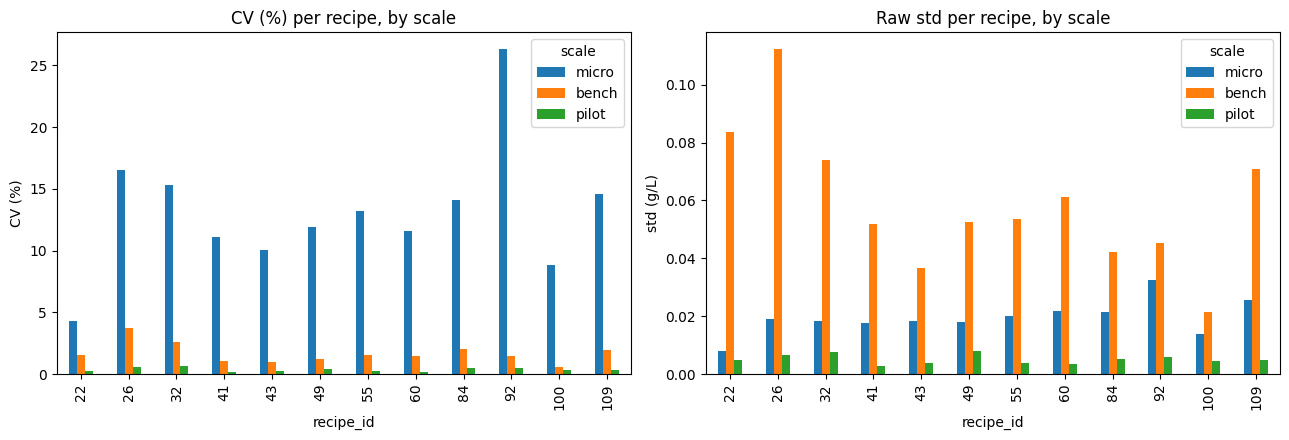

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

cv_plot = noise_stats.pivot(index="recipe_id", columns="scale", values="cv_pct")[scales]
cv_plot.plot(kind="bar", ax=axes[0])
axes[0].set_title("CV (%) per recipe, by scale")
axes[0].set_ylabel("CV (%)")
axes[0].set_xlabel("recipe_id")
axes[0].legend(title="scale")

std_plot = noise_stats.pivot(index="recipe_id", columns="scale", values="std")[scales]
std_plot.plot(kind="bar", ax=axes[1])
axes[1].set_title("Raw std per recipe, by scale")
axes[1].set_ylabel("std (g/L)")
axes[1].set_xlabel("recipe_id")
axes[1].legend(title="scale")

plt.tight_layout()
plt.show()

### Step 3: Is yield (g/L) really affected by scale? Quantifying bias

g/L is a *concentration*, so on paper itshouldn't care about reactor size the way a total mass or volume would.
But real bioreactors scale up in physically messy ways — mixing time,
oxygen transfer (kLa), shear stress and heat removal all behave differently
in a 1 L micro-reactor vs a pilot-scale tank, even for the *same*
temperature/pH/feed setpoints. So the same recipe can legitimately reach a
different achievable g/L at each scale. That's the classic "scale-up gap"
in bioprocessing, and it's a systematic (biased) effect, not noise.

Rather than assume this, we check it: for every recipe in the exploration
set (128 recipes, 1 run per scale), we compare each scale's yield to
pilot's yield for that same recipe, and fit a straight line:

`yield_scale ≈ intercept + slope * yield_pilot`

- slope ≈ 1 and intercept ≈ 0 → scales agree, no real bias.
- intercept far from 0 → an **additive** offset (scale runs consistently
  higher/lower by a fixed amount).
- slope far from 1 → a **multiplicative** effect (scale over/under-shoots
  proportionally to how well the recipe does at pilot).
- Real data is often a mix of both — the regression gives you both numbers.

In [17]:
from scipy.stats import linregress

# One row per recipe, one column per scale (single run each, from the 128-recipe sweep)
explore_wide = df_explore.pivot(index="recipe_id", columns="scale", values="yield").reset_index()
explore_wide = explore_wide[["recipe_id"] + scales]

bias_rows = []
for scale in scales:
    if scale == "pilot":
        slope, intercept, r, p, se = 1.0, 0.0, 1.0, 0.0, 0.0
    else:
        slope, intercept, r, p, se = linregress(explore_wide["pilot"], explore_wide[scale])
    bias_rows.append({
        "scale": scale,
        "intercept": intercept,
        "slope": slope,
        "r_squared": r**2,
        "mean_abs_diff_vs_pilot": (explore_wide[scale] - explore_wide["pilot"]).abs().mean(),
        "mean_signed_diff_vs_pilot": (explore_wide[scale] - explore_wide["pilot"]).mean(),
    })

bias_df = pd.DataFrame(bias_rows).set_index("scale").reindex(scales)
bias_df.round(4)

,intercept,slope,r_squared,mean_abs_diff_vs_pilot,mean_signed_diff_vs_pilot
scale,,,,,
micro,0.0943,0.0364,0.7391,1.5049,-1.5049
bench,1.1509,1.6342,0.9913,2.2033,2.2033
pilot,0.0000,1.0000,1.0000,0.0000,0.0000


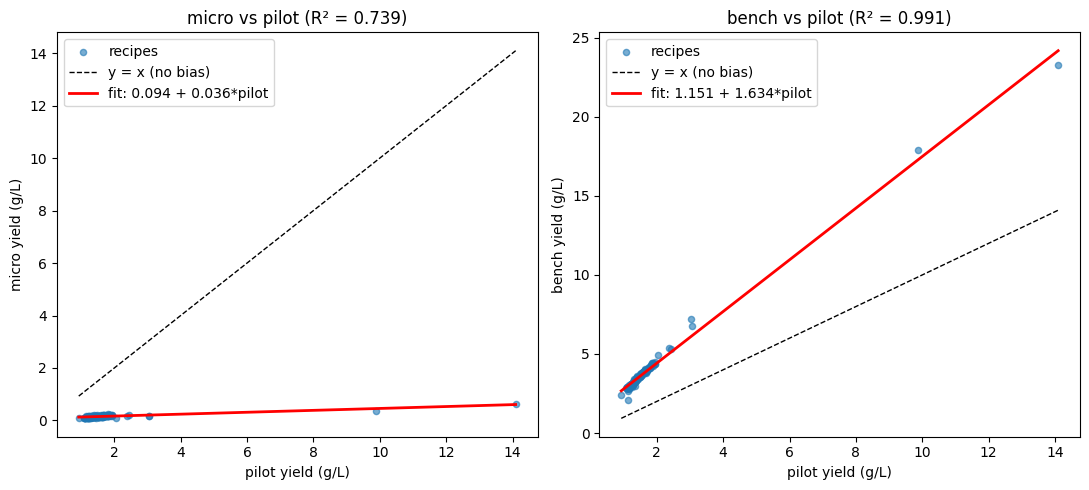

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(11, 5))

for ax, scale in zip(axes, ["micro", "bench"]):
    ax.scatter(explore_wide["pilot"], explore_wide[scale], alpha=0.6, s=20, label="recipes")

    lims = [explore_wide["pilot"].min(), explore_wide["pilot"].max()]
    ax.plot(lims, lims, "k--", linewidth=1, label="y = x (no bias)")

    slope, intercept = bias_df.loc[scale, "slope"], bias_df.loc[scale, "intercept"]
    xs = np.linspace(*lims, 50)
    ax.plot(xs, intercept + slope * xs, "r-", linewidth=2,
            label=f"fit: {intercept:.3f} + {slope:.3f}*pilot")

    ax.set_xlabel("pilot yield (g/L)")
    ax.set_ylabel(f"{scale} yield (g/L)")
    ax.set_title(f"{scale} vs pilot (R² = {bias_df.loc[scale, 'r_squared']:.3f})")
    ax.legend()

plt.tight_layout()
plt.show()

### Step 4: Master table — noise + bias per scale

One table combining both properties, in the units each downstream use
actually needs:

- `cv_pct` → for the report, to argue reliability in relative terms.
- `noise_variance` (= std², **not** std) → for `WhiteKernel(noise_level=...)`,
  since sklearn's `WhiteKernel` parameter is a variance, so passing std
  directly would understate the noise you're telling the GP about.
- `bias_intercept` / `bias_slope` → for aligning Micro/Bench onto Pilot
  before computing Expected Improvement, if you go with independent GPs
  per scale instead of one multi-fidelity GP.

In [19]:
scale_properties = pd.DataFrame({
    "mean_yield": noise_stats.groupby("scale")["mean"].mean(),
    "noise_std": noise_stats.groupby("scale")["std"].mean(),
}).reindex(scales)

scale_properties["noise_variance"] = scale_properties["noise_std"] ** 2
scale_properties["cv_pct"] = noise_stats.groupby("scale")["cv_pct"].mean().reindex(scales)
scale_properties["bias_intercept"] = bias_df["intercept"]
scale_properties["bias_slope"] = bias_df["slope"]
scale_properties["bias_r_squared"] = bias_df["r_squared"]

scale_properties = scale_properties[[
    "mean_yield", "noise_std", "noise_variance", "cv_pct",
    "bias_intercept", "bias_slope", "bias_r_squared"
]]

print("Scale properties -- noise (from 12 repeated recipes) + bias (from 128-recipe sweep, vs pilot):")
scale_properties.round(4)

Scale properties -- noise (from 12 repeated recipes) + bias (from 128-recipe sweep, vs pilot):


,mean_yield,noise_std,noise_variance,cv_pct,bias_intercept,bias_slope,bias_r_squared
scale,,,,,,,
micro,0.1549,0.0196,0.0004,13.1565,0.0943,0.0364,0.7391
bench,3.7014,0.0588,0.0035,1.6716,1.1509,1.6342,0.9913
pilot,1.5690,0.0052,0.0000,0.3548,0.0000,1.0000,1.0000
